# **Clasificación de la forma reportada en avistamientos de OVNIS en Estados Unidos mediante aprendizaje automático**

**Alumno:** Ariel Tuñon  
**Institución:** Politécnico Superior Malvinas Argentinas   
**Año:** 2026

---

# DATOS LIMPIOS Y PREPARADOS - CARGA DE LIBRERIAS Y DATASET

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings('ignore')
import cufflinks as cf
import plotly.offline
cf.go_offline()
cf.set_config_file(offline=False, world_readable=True)

# URL en formato raw del archivo CSV en tu repositorio de GitHub
url_csv = "https://raw.githubusercontent.com/arieltunon74/Aprendizaje_automatico_parcial_2026/refs/heads/main/data/processed/dataset_procesado.csv"

print("Cargando el dataset procesado desde GitHub...")
# Especificamos sep=';' ya que el archivo utiliza punto y coma como delimitador
df_procesado = pd.read_csv(url_csv, sep=';')

print("\n¡Dataset procesado cargado exitosamente!")
print(f"Total de registros (filas): {df_procesado.shape[0]:,}")
print(f"Total de columnas: {df_procesado.shape[1]}")

Cargando el dataset procesado desde GitHub...

¡Dataset procesado cargado exitosamente!
Total de registros (filas): 111,741
Total de columnas: 28


# VISUALIZACIÓN DE LOS DATOS

In [2]:
# Nombres de las columnas
print("\nColumnas:")
print(df_procesado.columns.tolist())

# Información general
print("\nInformación del dataset:")
df_procesado.info()


Columnas:
['id', 'occurred_date_time', 'city', 'state', 'shape', 'duration', 'summary', 'details_url', 'posted_date', 'year', 'state_grouped', 'duration_seconds', 'duration_seconds_isna', 'month', 'hour', 'day_of_week', 'occurred_datetime', 'month_category', 'north_season', 'day_category', 'Duracion_clasificacion', 'time_of_day', 'is_weekend', 'shape_grouped', 'decade', 'duration_category_detailed', 'us_region', 'quarter_category']

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111741 entries, 0 to 111740
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   id                          111741 non-null  int64 
 1   occurred_date_time          111741 non-null  object
 2   city                        111741 non-null  object
 3   state                       111741 non-null  object
 4   shape                       111741 non-null  object
 5   duration              


#ANÁLISIS EXPLORATORIO DE DATOS (EDA)

##Inspección de filas, columnas, tipos de datos y estadísticas

---

###Procedimientos de inspección

1. Visualización de registros iniciales y finales.
2. Análisis y exploración de la variable objetivo y las demás variables
2. Consulta de las dimensiones del DataFrame.
3. Revisión de nombres y tipos de columnas.
4. Obtención de estadísticas descriptivas.
5. Identificación de valores faltantes y duplicados.

---


---

### LAS COLUMNAS id, summary Y details_url -- NO SE TENDRÁN EN CUENTA EN EL MODELO

---



## 1. Visualización de registros iniciales y finales

### Primeras 10 filas del dataset

In [3]:
# Ver las primeras 10 filas del dataset
print("\n--- Primeras filas del dataset (.head()) ---")
display(df_procesado.head(10))




--- Primeras filas del dataset (.head()) ---


,id,occurred_date_time,city,state,shape,duration,summary,details_url,posted_date,year,...,north_season,day_category,Duracion_clasificacion,time_of_day,is_weekend,shape_grouped,decade,duration_category_detailed,us_region,quarter_category
0,147518,12/7/2019 09:20,Redding,CA,Cylinder,5 minutes,"North Redding, CA. We saw a bright flashing w...",http://www.nuforc.org/webreports/147/S147518.html,7/12/2019,2019,...,Verano,Viernes,Corto,Mañana,Fin de semana,Otras,2010s,Moderada,West,Q3 (Jul-Sep)
1,147514,12/7/2019 03:30,Charlotte,NC,Other,20 minutes,Whooshing sound with 1-red and 3-white lights ...,http://www.nuforc.org/webreports/147/S147514.html,7/12/2019,2019,...,Verano,Viernes,Medio,Madrugada,Fin de semana,Other,2010s,Prolongada,South,Q3 (Jul-Sep)
2,147511,11/7/2019 22:40,Cedar Creek,TX,Other,20 seconds,"Sitting on my front porch a few minutes ago, w...",http://www.nuforc.org/webreports/147/S147511.html,7/12/2019,2019,...,Verano,Jueves,Muy corto,Noche,Día de semana,Other,2010s,Breve,South,Q3 (Jul-Sep)
3,147512,11/7/2019 22:10,San Bernardino,CA,Triangle,2 minutes,On the freeway on my way home from a distance....,http://www.nuforc.org/webreports/147/S147512.html,7/12/2019,2019,...,Verano,Jueves,Corto,Noche,Día de semana,Triangle,2010s,Moderada,West,Q3 (Jul-Sep)
4,147509,11/7/2019 22:00,Bowling Green,KY,Other,45 minutes,Me and my girlfriend watched as we first seen ...,http://www.nuforc.org/webreports/147/S147509.html,7/12/2019,2019,...,Verano,Jueves,Largo,Noche,Día de semana,Other,2010s,Prolongada,South,Q3 (Jul-Sep)
5,147515,11/7/2019 21:30,Dayton,NV,Circle,2 minutes,Two points of light rotating around a center p...,http://www.nuforc.org/webreports/147/S147515.html,7/12/2019,2019,...,Verano,Jueves,Corto,Noche,Día de semana,Circle,2010s,Moderada,West,Q3 (Jul-Sep)
6,147507,11/7/2019 20:25,Lakeland/Nashville border,GA,Changing,2 minutes,UFO makes contact with commercial aircraft.,http://www.nuforc.org/webreports/147/S147507.html,7/12/2019,2019,...,Verano,Jueves,Corto,Noche,Día de semana,Otras,2010s,Moderada,South,Q3 (Jul-Sep)
7,147508,11/7/2019 19:30,Pleasanton,CA,Light,5 minutes,Shiny object in the NE sky above N California....,http://www.nuforc.org/webreports/147/S147508.html,7/12/2019,2019,...,Verano,Jueves,Corto,Noche,Día de semana,Light,2010s,Moderada,West,Q3 (Jul-Sep)
8,147489,11/7/2019 05:15,Boise,ID,Circle,5 seconds,Greenish blue circular light moving at high sp...,http://www.nuforc.org/webreports/147/S147489.html,7/12/2019,2019,...,Verano,Jueves,Muy corto,Madrugada,Día de semana,Circle,2010s,Muy breve,West,Q3 (Jul-Sep)
9,147490,11/7/2019 02:50,Franklin-Alvadore,OR,Light,60 seconds,I observed what looked to be a star or planet ...,http://www.nuforc.org/webreports/147/S147490.html,7/12/2019,2019,...,Verano,Jueves,Muy corto,Madrugada,Día de semana,Light,2010s,Breve,West,Q3 (Jul-Sep)


### Últimas 10 filas del dataset

In [4]:
# Ver las últimas 10 filas del dataset
print("\n--- Últimas filas del dataset (.tail()) ---")
display(df_procesado.tail(10))


--- Últimas filas del dataset (.tail()) ---


,id,occurred_date_time,city,state,shape,duration,summary,details_url,posted_date,year,...,north_season,day_category,Duracion_clasificacion,time_of_day,is_weekend,shape_grouped,decade,duration_category_detailed,us_region,quarter_category
111731,2902,18/11/1997 14:36,Oswego,NY,Other,10min,i was walking home with a friend when she saw ...,http://www.nuforc.org/webreports/002/S02902.html,NaN,1997,...,Otoño,Martes,Medio,Tarde,Día de semana,Other,1990s,Prolongada,Northeast,Q4 (Oct-Dic)
111732,10555,1/3/1997 14:00,Jacksonville,FL,Changing,unknown,I was standing outside and i saw an object fly...,http://www.nuforc.org/webreports/010/S10555.html,NaN,1997,...,Primavera,Sábado,Medio,Tarde,Fin de semana,Otras,1990s,Prolongada,South,Q1 (Ene-Mar)
111733,10372,1/1/1983 13:00,Wilton,NY,Disk,a few sec.,Sometime around noon between spring and summer...,http://www.nuforc.org/webreports/010/S10372.html,11/2/1999,1983,...,Invierno,Sábado,Corto,Tarde,Fin de semana,Disk,1980s,Moderada,Northeast,Q1 (Ene-Mar)
111734,17986,1/1/2000 07:00,Higgans Lake,MI,Disk,unknown,It was green with flashing lights.,http://www.nuforc.org/webreports/017/S17986.html,8/5/2001,2000,...,Invierno,Sábado,Corto,Mañana,Fin de semana,Disk,2000s,Moderada,Midwest,Q1 (Ene-Mar)
111735,14750,1/4/2000 06:30,London (UK/England),unknown,Fireball,10 seconds,A luminous green orb object over London,http://www.nuforc.org/webreports/014/S14750.html,12/2/2000,2000,...,Primavera,Sábado,Muy corto,Mañana,Fin de semana,Fireball,2000s,Muy breve,Otra / Internacional,Q2 (Abr-Jun)
111736,5240,24/12/1998 06:24,Bartlett,IL,Cigar,25 secs.,at 6:24 P.M. i saw a cigar shaped object w/ re...,http://www.nuforc.org/webreports/005/S05240.html,NaN,1998,...,Invierno,Jueves,Muy corto,Mañana,Día de semana,Otras,1990s,Breve,Midwest,Q4 (Oct-Dic)
111737,8323,11/7/1999 04:30,New York City (Bronx),NY,Light,1.5 min.,I was talking with a friend outside her buildi...,http://www.nuforc.org/webreports/008/S08323.html,NaN,1999,...,Verano,Domingo,Corto,Madrugada,Fin de semana,Light,1990s,Moderada,Northeast,Q3 (Jul-Sep)
111738,13480,1/11/1995 03:00,St. Martin (French West Indies),unknown,Oval,3-5 min.,I saw glowing orange oval stationery craft on...,http://www.nuforc.org/webreports/013/S13480.html,NaN,1995,...,Otoño,Miércoles,Corto,Madrugada,Día de semana,Otras,1990s,Moderada,Otra / Internacional,Q4 (Oct-Dic)
111739,13952,1/8/1987 01:00,Fort Carson,CO,Light,5-min,Saw light moving erratically in the sky east o...,http://www.nuforc.org/webreports/013/S13952.html,NaN,1987,...,Verano,Sábado,Muy corto,Madrugada,Fin de semana,Light,1980s,Muy breve,West,Q3 (Jul-Sep)
111740,14263,1/7/1984 00:30,Kentville (Canada),NS,Light,unknown,Hello my name is Donnie Duffy. i was camping ...,http://www.nuforc.org/webreports/014/S14263.html,12/2/2000,1984,...,Verano,Domingo,Corto,Madrugada,Fin de semana,Light,1980s,Moderada,Otra / Internacional,Q3 (Jul-Sep)



## 1. ANÁLISIS DE CLASES DE LA VARIABLE PREDICTORA `SHAPE`

### (FORMA DEL OVNI / UFO / UAP EN TODO EL MUNDO)


---

##Exploración de la variable objetivo y otras


========== VARIABLE OBJETIVO: SHAPE ==========

Cantidad de variables del dataset: 28
Cantidad de clases de Shape: 29

Formas de OVNI registradas:
['Cylinder' 'Other' 'Triangle' 'Circle' 'Changing' 'Light' 'Unknown'
 'Sphere' 'Cigar' 'Fireball' 'Oval' 'Flash' 'Rectangle' 'Formation' 'Disk'
 'Egg' 'Teardrop' 'Chevron' 'Diamond' 'Cross' 'Cone' 'Hexagon' 'Flare'
 'Crescent' 'Delta' 'diamond' 'pyramid' 'Round' 'Dome']

Cantidad de frecuencia de registros por forma:


,Cantidad de registros
shape,
Light,23777
Circle,11992
Triangle,10914
Fireball,8890
Unknown,8087
Other,7973
Sphere,7603
Disk,6358
Oval,5052


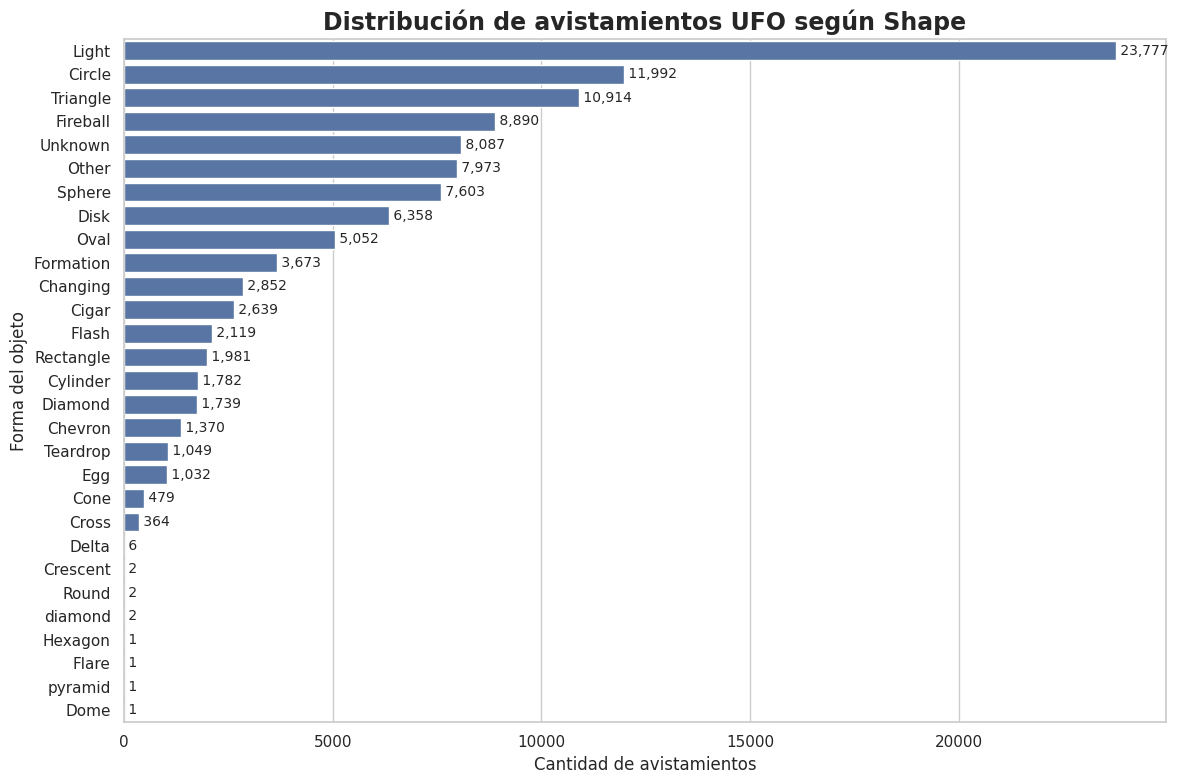

In [5]:
# ============================================
# ANÁLISIS DE LA VARIABLE OBJETIVO: SHAPE
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# --------------------------------------------
# Información general
# --------------------------------------------

print("========== VARIABLE OBJETIVO: SHAPE ==========")

print(f"\nCantidad de variables del dataset: {len(df_procesado.columns)}")
print(f"Cantidad de clases de Shape: {df_procesado['shape'].nunique()}")

print("\nFormas de OVNI registradas:")
print(df_procesado["shape"].dropna().unique())

# --------------------------------------------
# Frecuencia de cada clase
# --------------------------------------------

frecuencias = (
    df_procesado["shape"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de frecuencia de registros por forma:")
display(frecuencias.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn
# --------------------------------------------

plt.figure(figsize=(12, 8))

sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index
)

plt.title(
    "Distribución de avistamientos UFO según Shape",
    fontsize=17,
    fontweight="bold"
)

plt.xlabel("Cantidad de avistamientos")
plt.ylabel("Forma del objeto")

# Mostrar valores
for i, valor in enumerate(frecuencias.values):
    plt.text(
        valor,
        i,
        f" {valor:,}",
        va="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

## 3. Consulta de las dimensiones del DataFrame Limpio

In [6]:
# Consultar las dimensiones del DataFrame
print(f"\n--- Dimensiones del DataFrame (.shape) ---")
print(f"Total de filas: {df_procesado.shape[0]:,}")
print(f"Total de columnas: {df_procesado.shape[1]:,}")

# También puedes ver la tupla completa directamente
print(f"Tupla (filas, columnas): {df_procesado.shape}")


--- Dimensiones del DataFrame (.shape) ---
Total de filas: 111,741
Total de columnas: 28
Tupla (filas, columnas): (111741, 28)


## 4. Revisión de nombres y tipos de columnas.

In [7]:
# Revisión completa de nombres, tipos de datos y valores nulos
print("\n--- Información general del DataFrame (.info()) ---")
df_procesado.info()

# Si solo quieres ver la lista de los nombres de las columnas:
print("\n--- Nombres de las columnas (.columns) ---")
print(list(df_procesado.columns))

# Si solo quieres ver los tipos de datos de cada columna (.dtypes):
print("\n--- Tipos de datos por columna (.dtypes) ---")
print(df_procesado.dtypes)


--- Información general del DataFrame (.info()) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 111741 entries, 0 to 111740
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   id                          111741 non-null  int64 
 1   occurred_date_time          111741 non-null  object
 2   city                        111741 non-null  object
 3   state                       111741 non-null  object
 4   shape                       111741 non-null  object
 5   duration                    111741 non-null  object
 6   summary                     111741 non-null  object
 7   details_url                 111741 non-null  object
 8   posted_date                 51460 non-null   object
 9   year                        111741 non-null  int64 
 10  state_grouped               111741 non-null  object
 11  duration_seconds            111741 non-null  int64 
 12  duration_seconds_isna       11174

## 5. Obtención de estadísticas descriptivas.

In [8]:
# Estadísticas descriptivas básicas para columnas numéricas
print("\n--- Estadísticas de columnas numéricas (.describe()) ---")
display(df_procesado.describe())

# Estadísticas descriptivas incluyendo columnas de texto (categóricas)
print("\n--- Estadísticas incluyendo columnas categóricas (.describe(include='all')) ---")
display(df_procesado.describe(include='all'))

# OTRO

print("\n========== RESUMEN ESTADÍSTICO ==========")
display(df_procesado.describe(include="all").T)


--- Estadísticas de columnas numéricas (.describe()) ---


,id,year,duration_seconds,duration_seconds_isna,month,hour,day_of_week
count,111741.000000,111741.000000,111741.000000,111741.000000,111741.000000,111741.000000,111741.000000
mean,77322.143904,2008.003777,613.564779,0.103803,6.851988,15.511433,3.177195
std,40235.282879,7.878963,1370.187653,0.305006,3.243094,7.758369,1.983035
min,113.000000,1962.000000,1.000000,0.000000,1.000000,0.000000,0.000000
25%,44295.000000,2004.000000,30.000000,0.000000,4.000000,10.000000,1.000000
50%,78305.000000,2010.000000,180.000000,0.000000,7.000000,19.000000,3.000000
75%,111615.000000,2014.000000,600.000000,0.000000,10.000000,21.000000,5.000000
max,147520.000000,2021.000000,10800.000000,1.000000,12.000000,23.000000,6.000000



--- Estadísticas incluyendo columnas categóricas (.describe(include='all')) ---


,id,occurred_date_time,city,state,shape,duration,summary,details_url,posted_date,year,...,north_season,day_category,Duracion_clasificacion,time_of_day,is_weekend,shape_grouped,decade,duration_category_detailed,us_region,quarter_category
count,111741.000000,111741,111741,111741,111741,111741,111741,111741,51460,111741.000000,...,111741,111741,111741,111741,111741,111741,111741,111741,111741,111741
unique,NaN,95067,24138,71,29,11249,111117,111741,238,NaN,...,4,7,4,4,2,9,7,4,5,4
top,NaN,7/11/2015 18:00,Phoenix,CA,Light,5 minutes,((NUFORC Note: No information provided by wit...,http://www.nuforc.org/webreports/014/S14263.html,12/12/2009,NaN,...,Verano,Sábado,Corto,Noche,Día de semana,Otras,2010s,Moderada,West,Q3 (Jul-Sep)
freq,NaN,103,630,12727,23777,6958,31,1,1540,NaN,...,35689,20148,40980,62570,58883,26147,56497,40980,33577,35671
mean,77322.143904,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2008.003777,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,40235.282879,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.878963,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,113.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1962.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,44295.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2004.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,78305.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2010.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,111615.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



========== RESUMEN ESTADÍSTICO ==========


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,111741.0,NaN,NaN,NaN,77322.143904,40235.282879,113.0,44295.0,78305.0,111615.0,147520.0
occurred_date_time,111741,95067,7/11/2015 18:00,103,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,111741,24138,Phoenix,630,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,111741,71,CA,12727,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shape,111741,29,Light,23777,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,111741,11249,5 minutes,6958,NaN,NaN,NaN,NaN,NaN,NaN,NaN
summary,111741,111117,((NUFORC Note: No information provided by wit...,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN
details_url,111741,111741,http://www.nuforc.org/webreports/014/S14263.html,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
posted_date,51460,238,12/12/2009,1540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year,111741.0,NaN,NaN,NaN,2008.003777,7.878963,1962.0,2004.0,2010.0,2014.0,2021.0


## 6. Identificación de valores faltantes y duplicados.

========== INFORMACIÓN DEL DATASET ==========

Cantidad de registros: 111,741
Cantidad de variables: 28

========== NOMBRES DE LAS VARIABLES ==========
1. id
2. occurred_date_time
3. city
4. state
5. shape
6. duration
7. summary
8. details_url
9. posted_date
10. year
11. state_grouped
12. duration_seconds
13. duration_seconds_isna
14. month
15. hour
16. day_of_week
17. occurred_datetime
18. month_category
19. north_season
20. day_category
21. Duracion_clasificacion
22. time_of_day
23. is_weekend
24. shape_grouped
25. decade
26. duration_category_detailed
27. us_region
28. quarter_category

========== TIPOS DE DATOS ==========
id                             int64
occurred_date_time            object
city                          object
state                         object
shape                         object
duration                      object
summary                       object
details_url                   object
posted_date                   object
year                           in

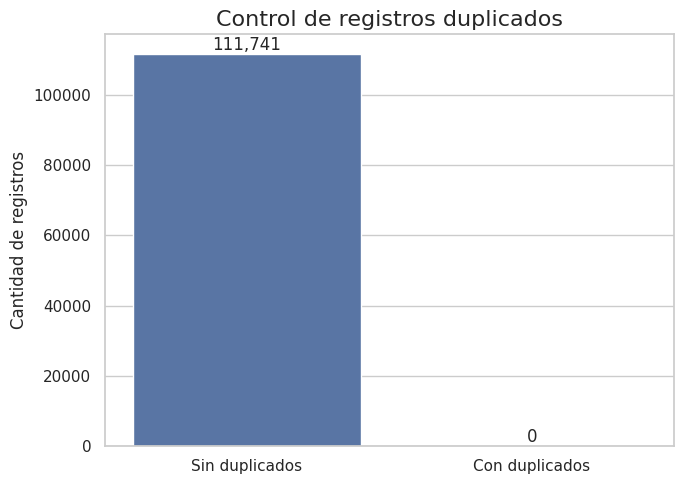

In [9]:
# Exploración inicial del dataset

print("========== INFORMACIÓN DEL DATASET ==========")
print(f"\nCantidad de registros: {df_procesado.shape[0]:,}")
print(f"Cantidad de variables: {df_procesado.shape[1]}")
print("\n========== NOMBRES DE LAS VARIABLES ==========")
for i, columna in enumerate(df_procesado.columns, start=1):
    print(f"{i}. {columna}")

print("\n========== TIPOS DE DATOS ==========")
print(df_procesado.dtypes)

print("\n========== REGISTROS DUPLICADOS ==========")
# Duplicados
duplicados = df_procesado.duplicated().sum()
print("\n🔹 REGISTROS DUPLICADOS")
print(f"   {duplicados:,} registros duplicados")
print("\n" * 2)

duplicados = df_procesado.duplicated().sum()
resultado = pd.DataFrame({
    "Estado": ["Sin duplicados", "Con duplicados"],
    "Cantidad": [
        len(df_procesado) - duplicados,
        duplicados
    ]
})

plt.figure(figsize=(7, 5))

sns.barplot(
    data=resultado,
    x="Estado",
    y="Cantidad"
)

plt.title("Control de registros duplicados", fontsize=16)
plt.xlabel("")
plt.ylabel("Cantidad de registros")

for i, valor in enumerate(resultado["Cantidad"]):
    plt.text(i, valor, f"{valor:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


## VEIFICACIÓN DE VALORES NULOS

In [10]:
import numpy as np
import pandas as pd

# =========================================================
# 1. DIAGNÓSTICO COMPLETO DE VALORES NULOS
# =========================================================


def diagnostico_nulos(df):
    nulos_cant = df.isnull().sum()
    nulos_porc = (df.isnull().mean() * 100).round(2)

    df_diagnostico = pd.DataFrame(
        {"Cantidad_Nulos": nulos_cant, "Porcentaje_Nulos(%)": nulos_porc}
    )

    return df_diagnostico[df_diagnostico["Cantidad_Nulos"] > 0].sort_values(
        by="Porcentaje_Nulos(%)", ascending=False
    )


print("--- DIAGNÓSTICO INICIAL DE NULOS ---")
df_nulos_info = diagnostico_nulos(df_procesado)

if not df_nulos_info.empty:
    display(df_nulos_info.style.background_gradient(cmap="Reds"))
else:
    print("¡El dataset está completamente libre de valores nulos!")


# =========================================================
# 2. ESTRATEGIA DE LIMPIEZA GENERAL
# =========================================================

# A. Opcional: Eliminar columnas que tengan un porcentaje crítico de nulos (ej. mayor al 50%)
umbral_columnas = 0.50
cols_validas = df_procesado.columns[df_procesado.isnull().mean() <= umbral_columnas]
df_procesado = df_procesado[cols_validas]

# B. Imputación para variables NUMÉRICAS (usando la mediana para evitar sesgos por outliers)
cols_num = df_procesado.select_dtypes(include=[np.number]).columns
for col in cols_num:
    if df_procesado[col].isnull().sum() > 0:
        mediana_val = df_procesado[col].median()
        df_procesado[col] = df_procesado[col].fillna(mediana_val)

# C. Imputación para variables CATEGÓRICAS / TEXTO (etiquetando como "Desconocido")
cols_cat = df_procesado.select_dtypes(include=["object", "string"]).columns
for col in cols_cat:
    if df_procesado[col].isnull().sum() > 0:
        df_procesado[col] = df_procesado[col].fillna("Desconocido")

# D. Limpieza final: Eliminar cualquier fila remanente que aún contenga nulos críticos
df_procesado = df_procesado.dropna().reset_index(drop=True)

print(
    f"\n✅ Limpieza completada. Dimensiones finales del DataFrame: {df_procesado.shape}"
)

--- DIAGNÓSTICO INICIAL DE NULOS ---


,Cantidad_Nulos,Porcentaje_Nulos(%)
posted_date,60281,53.950000



✅ Limpieza completada. Dimensiones finales del DataFrame: (111741, 27)


### **NUEVO ANÁLISIS PARA VER RESULTADOS EN LA VARIABLE OBJETIVO: `shape` (FORMA DEL OBJETO)**

Descartar Light, Other,Unknown,Delta,Crescent,Round,diamond,Hexagon,Flare,Dome,


In [11]:
# Lista de formas que deseas descartar (en minúsculas para abarcar todas las variantes)
formas_a_descartar = [
    "light", "other", "unknown", "delta", "crescent",
    "round", "diamond", "hexagon", "flare", "dome", "pyramid"
]

# Inicializamos df_limpio a partir del DataFrame activo 'df_procesado'
df_limpio = df_procesado.copy()

# Filtrar el DataFrame descartando los registros cuyas formas estén en la lista
# Usamos .str.lower() y .astype(str) para evitar errores con nulos (NaN) o diferencias de mayúsculas
df_limpio = df_limpio[~df_limpio["shape"].astype(str).str.lower().isin(formas_a_descartar)]

print(f"Registros restantes después de filtrar: {df_limpio.shape[0]:,}")

# Verificar cómo quedó el conteo de formas actualizado
print("\n--- Conteo de formas resultante ---")
display(df_limpio["shape"].value_counts())

Registros restantes después de filtrar: 70,149

--- Conteo de formas resultante ---


,count
shape,
Circle,11992
Triangle,10914
Fireball,8890
Sphere,7603
Disk,6358
Oval,5052
Formation,3673
Changing,2852
Cigar,2639


# FILTRADO GEOGRÁFICO

In [12]:
import pandas as pd

# Lista oficial de abreviaturas de estados de EE. UU. (incluyendo Washington D.C.)
abreviaturas_usa = {
    'AL', 'AK', 'AZ', 'AR', 'CA', 'CO', 'CT', 'DE', 'FL', 'GA',
    'HI', 'ID', 'IL', 'IN', 'IA', 'KS', 'KY', 'LA', 'ME', 'MD',
    'MA', 'MI', 'MN', 'MS', 'MO', 'MT', 'NE', 'NV', 'NH', 'NJ',
    'NM', 'NY', 'NC', 'ND', 'OH', 'OK', 'OR', 'PA', 'RI', 'SC',
    'SD', 'TN', 'TX', 'UT', 'VT', 'VA', 'WA', 'WV', 'WI', 'WY',
    'DC'
}

# Normalizar la columna 'state' (quitar espacios y pasar a mayúsculas) para una comparación segura
df_procesado['state_clean'] = df_procesado['state'].astype(str).str.strip().str.upper()

# Filtrar el DataFrame original
df_usa = df_procesado[df_procesado['state_clean'].isin(abreviaturas_usa)].copy()

# Eliminar la columna temporal de normalización
df_usa = df_usa.drop(columns=['state_clean'])
df_procesado = df_procesado.drop(columns=['state_clean'])

# Mostrar resultados del filtrado
print("========== FILTRADO GEOGRÁFICO (USA) ==========")
print(f"Registros totales originales: {df_procesado.shape[0]:,}")
print(f"Registros seleccionados de EE. UU.: {df_usa.shape[0]:,}")
print(f"Registros excluidos: {df_procesado.shape[0] - df_usa.shape[0]:,}")

# Mostrar las primeras filas del dataset filtrado
display(df_usa.head())

========== FILTRADO GEOGRÁFICO (USA) ==========
Registros totales originales: 111,741
Registros seleccionados de EE. UU.: 99,202
Registros excluidos: 12,539


,id,occurred_date_time,city,state,shape,duration,summary,details_url,year,state_grouped,...,north_season,day_category,Duracion_clasificacion,time_of_day,is_weekend,shape_grouped,decade,duration_category_detailed,us_region,quarter_category
0,147518,12/7/2019 09:20,Redding,CA,Cylinder,5 minutes,"North Redding, CA. We saw a bright flashing w...",http://www.nuforc.org/webreports/147/S147518.html,2019,CA,...,Verano,Viernes,Corto,Mañana,Fin de semana,Otras,2010s,Moderada,West,Q3 (Jul-Sep)
1,147514,12/7/2019 03:30,Charlotte,NC,Other,20 minutes,Whooshing sound with 1-red and 3-white lights ...,http://www.nuforc.org/webreports/147/S147514.html,2019,Other,...,Verano,Viernes,Medio,Madrugada,Fin de semana,Other,2010s,Prolongada,South,Q3 (Jul-Sep)
2,147511,11/7/2019 22:40,Cedar Creek,TX,Other,20 seconds,"Sitting on my front porch a few minutes ago, w...",http://www.nuforc.org/webreports/147/S147511.html,2019,TX,...,Verano,Jueves,Muy corto,Noche,Día de semana,Other,2010s,Breve,South,Q3 (Jul-Sep)
3,147512,11/7/2019 22:10,San Bernardino,CA,Triangle,2 minutes,On the freeway on my way home from a distance....,http://www.nuforc.org/webreports/147/S147512.html,2019,CA,...,Verano,Jueves,Corto,Noche,Día de semana,Triangle,2010s,Moderada,West,Q3 (Jul-Sep)
4,147509,11/7/2019 22:00,Bowling Green,KY,Other,45 minutes,Me and my girlfriend watched as we first seen ...,http://www.nuforc.org/webreports/147/S147509.html,2019,Other,...,Verano,Jueves,Largo,Noche,Día de semana,Other,2010s,Prolongada,South,Q3 (Jul-Sep)


# RESULTADO: NUEVA VISUALIZACIÓN DE LA VARIABLE OBJETIVO: `shape` (FORMA DEL OBJETO)

========== VARIABLE OBJETIVO: SHAPE (FILTRADO) ==========

Cantidad de registros originales: 111,741
Cantidad de registros después del filtro: 70,149
Cantidad de clases restantes de Shape: 17

Cantidad de registros por forma (filtrado):


,Cantidad de registros
shape,
Circle,11992
Triangle,10914
Fireball,8890
Sphere,7603
Disk,6358
Oval,5052
Formation,3673
Changing,2852
Cigar,2639


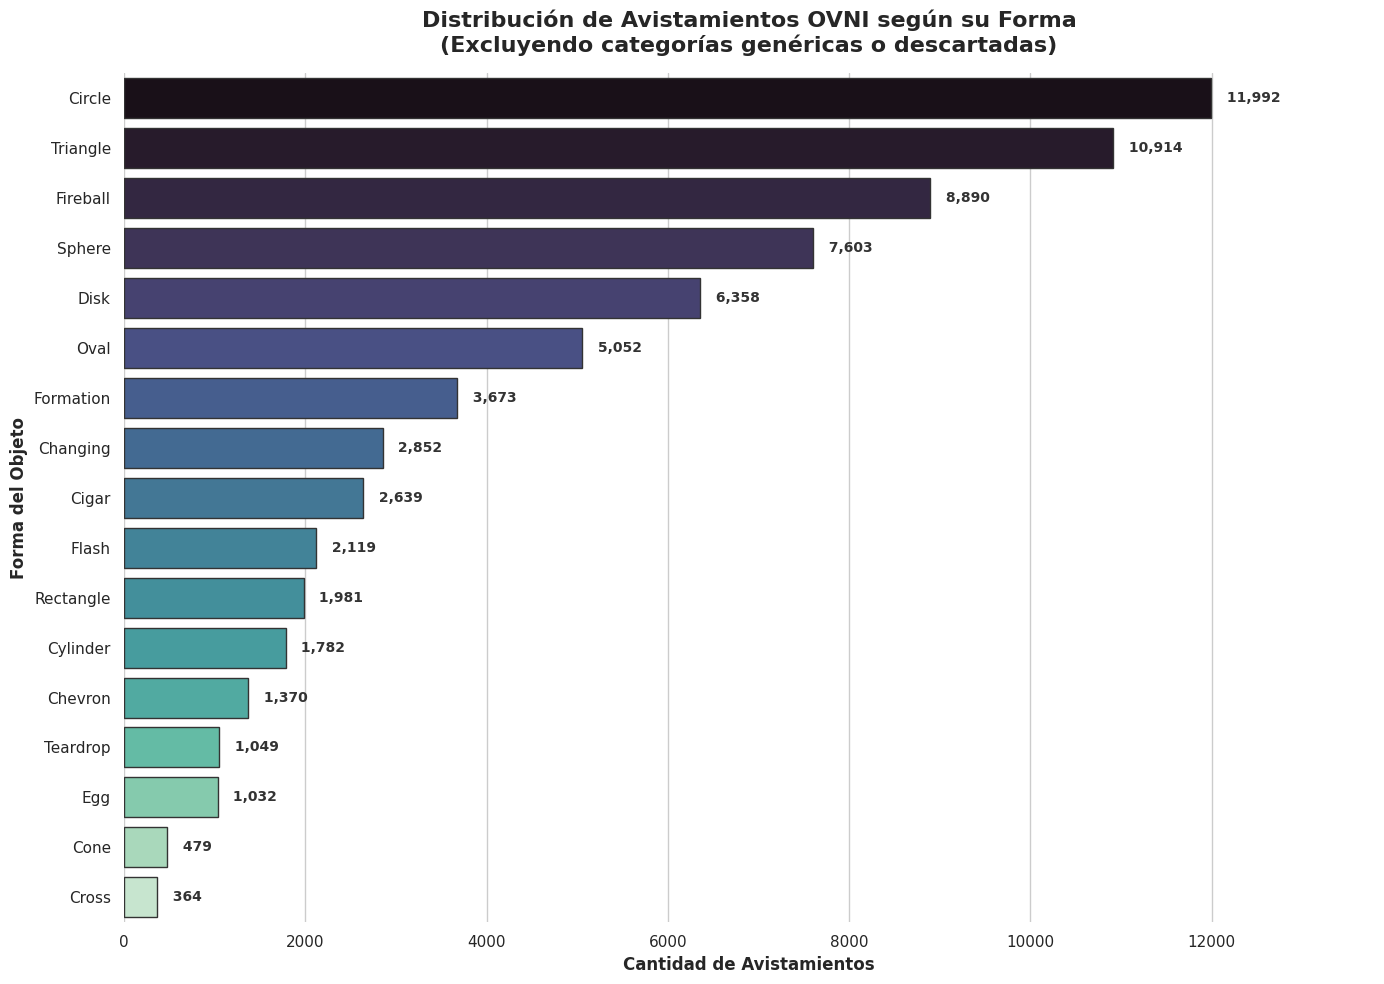

In [13]:
# ============================================
# ANÁLISIS DE LA VARIABLE OBJETIVO: SHAPE (Filtrado)
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de estilo
sns.set_theme(style="whitegrid")

# 1. Definir la lista de formas a descartar (en minúsculas)
descartar = [
    "light", "other", "unknown", "delta", "crescent",
    "round", "diamond", "hexagon", "flare", "dome", "pyramid","2013"
]

# 2. Filtrar el DataFrame excluyendo esas formas (insensible a mayúsculas/minúsculas y espacios)
df_filtrado = df_procesado[~df_procesado["shape"].astype(str).str.lower().str.strip().isin(descartar)].copy()

# --------------------------------------------
# Información general del dataset filtrado
# --------------------------------------------
print("========== VARIABLE OBJETIVO: SHAPE (FILTRADO) ==========")
print(f"\nCantidad de registros originales: {len(df_procesado):,}")
print(f"Cantidad de registros después del filtro: {len(df_filtrado):,}")
print(f"Cantidad de clases restantes de Shape: {df_filtrado['shape'].nunique()}")

# --------------------------------------------
# Frecuencia de cada clase restante
# --------------------------------------------
frecuencias = (
    df_filtrado["shape"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de registros por forma (filtrado):")
display(frecuencias.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn (Más vistoso)
# --------------------------------------------
plt.figure(figsize=(14, 10))

ax = sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index,
    hue=frecuencias.index,
    palette="mako",
    legend=False,
    edgecolor=".2"
)

plt.title(
    "Distribución de Avistamientos OVNI según su Forma\n(Excluyendo categorías genéricas o descartadas)",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Cantidad de Avistamientos", fontsize=12, fontweight="bold")
plt.ylabel("Forma del Objeto", fontsize=12, fontweight="bold")

# Extender ligeramente el eje X para que los números no se corten
plt.xlim(0, frecuencias.values.max() * 1.15)

# Mostrar valores numéricos al lado de cada barra
for i, valor in enumerate(frecuencias.values):
    ax.text(
        valor + (frecuencias.values.max() * 0.01),
        i,
        f" {valor:,}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="semibold",
        color="#333333"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## FILTRADO DE ESTADOS DE EE.UU - SE EXCLUYE RESTO DEL MUNDO (OTHER)

In [14]:
import pandas as pd

# 1. Utilizar el dataset cargado en memoria para evitar el FileNotFoundError
df = df_procesado.copy()

# 2. Definir los estados de Estados Unidos
estados_usa = {
    "ALABAMA", "ALASKA", "ARIZONA", "ARKANSAS", "CALIFORNIA",
    "COLORADO", "CONNECTICUT", "DELAWARE", "FLORIDA", "GEORGIA",
    "HAWAII", "IDAHO", "ILLINOIS", "INDIANA", "IOWA", "KANSAS",
    "KENTUCKY", "LOUISIANA", "MAINE", "MARYLAND", "MASSACHUSETTS",
    "MICHIGAN", "MINNESOTA", "MISSISSIPPI", "MISSOURI", "MONTANA",
    "NEBRASKA", "NEVADA", "NEW HAMPSHIRE", "NEW JERSEY",
    "NEW MEXICO", "NEW YORK", "NORTH CAROLINA", "NORTH DAKOTA",
    "OHIO", "OKLAHOMA", "OREGON", "PENNSYLVANIA", "RHODE ISLAND",
    "SOUTH CAROLINA", "SOUTH DAKOTA", "TENNESSEE", "TEXAS", "UTAH",
    "VERMONT", "VIRGINIA", "WASHINGTON", "WEST VIRGINIA",
    "WISCONSIN", "WYOMING", "DISTRICT OF COLUMBIA"
}

abreviaturas_usa = {
    "AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE", "FL", "GA",
    "HI", "ID", "IL", "IN", "IA", "KS", "KY", "LA", "ME", "MD",
    "MA", "MI", "MN", "MS", "MO", "MT", "NE", "NV", "NH", "NJ",
    "NM", "NY", "NC", "ND", "OH", "OK", "OR", "PA", "RI", "SC",
    "SD", "TN", "TX", "UT", "VT", "VA", "WA", "WV", "WI", "WY",
    "DC"
}

# 3. Normalizar los valores de state
state_normalizado = (
    df["state"]
    .astype("string")
    .str.strip()
    .str.upper()
)

# 4. Seleccionar los registros de Estados Unidos
mascara_usa = (
    state_normalizado.isin(estados_usa)
    | state_normalizado.isin(abreviaturas_usa)
)

df_usa = df.loc[mascara_usa].copy()

# 5. Mostrar la cantidad de registros seleccionados
print("Total de registros originales:", len(df))
print("Registros seleccionados de Estados Unidos:", len(df_usa))
print("Registros excluidos:", len(df) - len(df_usa))

# 6. Analizar la distribución de shape
distribucion_shape = (
    df_usa["shape"]
    .value_counts(dropna=False)
    .rename_axis("Categoría_shape")
    .reset_index(name="Cantidad")
)

# 7. Calcular el porcentaje de cada categoría
distribucion_shape["Porcentaje"] = (
    distribucion_shape["Cantidad"] / len(df_usa) * 100
).round(2)

# 8. Identificar categorías minoritarias
distribucion_shape["Categoria_minoritaria"] = (
    distribucion_shape["Cantidad"] < 30
)

# 9. Mostrar resultados
print("\nDistribución de las categorías de shape:")
print(distribucion_shape.to_string(index=False))

# 10. Guardar los resultados para documentar el análisis
distribucion_shape.to_csv(
    "distribucion_shape_usa.csv",
    index=False,
    encoding="utf-8-sig"
)

# 11. Guardar el dataset filtrado
df_usa.to_csv(
    "dataset_usa.csv",
    index=False,
    encoding="utf-8-sig"
)

Total de registros originales: 111741
Registros seleccionados de Estados Unidos: 99202
Registros excluidos: 12539

Distribución de las categorías de shape:
Categoría_shape  Cantidad  Porcentaje  Categoria_minoritaria
          Light     21184       21.35                  False
         Circle     10579       10.66                  False
       Triangle      9840        9.92                  False
       Fireball      8055        8.12                  False
        Unknown      7257        7.32                  False
          Other      6962        7.02                  False
         Sphere      6744        6.80                  False
           Disk      5438        5.48                  False
           Oval      4445        4.48                  False
      Formation      3279        3.31                  False
       Changing      2552        2.57                  False
          Cigar      2323        2.34                  False
          Flash      1885        1.90              


# **ESTADO FINAL DEL DATASET DESPUÉS DEL PRE - PROCESAMIENTO**

Resultado del proceso de limpieza y preparación de los datos, con el objetivo de obtener un conjunto de datos consistente y adecuado para el desarrollo del modelo de aprendizaje automático.

Ahora tiene 28 columnas adicionales porque se pasaron variables de númericas a categóricas y 111,753 filas o instancias.


Asimismo, se evaluaron las categorías de `shape` para definir cuáles resultaban adecuadas para el objetivo de predicción.


In [15]:
# =========================================================
# 12. VERIFICACIÓN DEL ESTADO DEL DATASET FILTRADO (df_usa)
# =========================================================

print("\n" + "="*50)
print("--- ESTADO DEL DATASET FILTRADO (df_usa) ---")
print("="*50)

# A. Dimensiones y uso de memoria
print(f"• Dimensiones finales: {df_usa.shape[0]:,} filas y {df_usa.shape[1]} columnas.")
print(f"• Memoria utilizada: {df_usa.memory_usage(deep=True).sum() / (1024**2):.2f} MB")

# B. Conteo de valores nulos por columna en el dataset filtrado
nulos_usa = df_usa.isnull().sum()
nulos_usa_filtrados = nulos_usa[nulos_usa > 0]
if not nulos_usa_filtrados.empty:
    print("\n--- Valores nulos remanentes en df_usa ---")
    print(nulos_usa_filtrados.to_string())
else:
    print("\n¡Excelente! No quedan valores nulos en el dataset filtrado.")

# C. Comprobación de integridad de los estados
estados_unicos_resultantes = df_usa["state"].astype("string").str.strip().str.upper().unique()
estados_fuera_de_lista = [e for e in estados_unicos_resultantes if e not in estados_usa and e not in abreviaturas_usa]

if not estados_fuera_de_lista:
    print("\n✅ Integridad geográfica validada: Todos los registros pertenecen exclusivamente a EE. UU.")
else:
    print(f"\n⚠️ Advertencia: Se encontraron estados no listados: {estados_fuera_de_lista}")

# D. Vista previa de la estructura de datos y tipos
print("\n--- Tipos de datos y columnas ---")
print(df_usa.dtypes)


--- ESTADO DEL DATASET FILTRADO (df_usa) ---
• Dimensiones finales: 99,202 filas y 27 columnas.
• Memoria utilizada: 127.76 MB

¡Excelente! No quedan valores nulos en el dataset filtrado.

✅ Integridad geográfica validada: Todos los registros pertenecen exclusivamente a EE. UU.

--- Tipos de datos y columnas ---
id                             int64
occurred_date_time            object
city                          object
state                         object
shape                         object
duration                      object
summary                       object
details_url                   object
year                           int64
state_grouped                 object
duration_seconds               int64
duration_seconds_isna          int64
month                          int64
hour                           int64
day_of_week                    int64
occurred_datetime             object
month_category                object
north_season                  object
day_category       

### Distribución de la variable objetivo Shape en EE. UU -SE DECARTAN LIGHT Y UNKNOWN PORQUE NO REPRESENTAN UNA FORMA A CLASIFICAR

--- Distribución de Shape en el Dataset Filtrado (df_filtrado) ---


,Cantidad,Porcentaje (%)
shape,,
Circle,11992,17.10
Triangle,10914,15.56
Fireball,8890,12.67
Sphere,7603,10.84
Disk,6358,9.06
Oval,5052,7.20
Formation,3673,5.24
Changing,2852,4.07
Cigar,2639,3.76


========== VARIABLE OBJETIVO: SHAPE (FILTRADO EE. UU.) ==========

Cantidad de registros originales en df_usa: 99,202
Cantidad de registros después del filtro de shape: 62,270
Cantidad de clases restantes de Shape: 17

Cantidad de registros por forma (filtrado):


,Cantidad de registros
shape,
Circle,10579
Triangle,9840
Fireball,8055
Sphere,6744
Disk,5438
Oval,4445
Formation,3279
Changing,2552
Cigar,2323


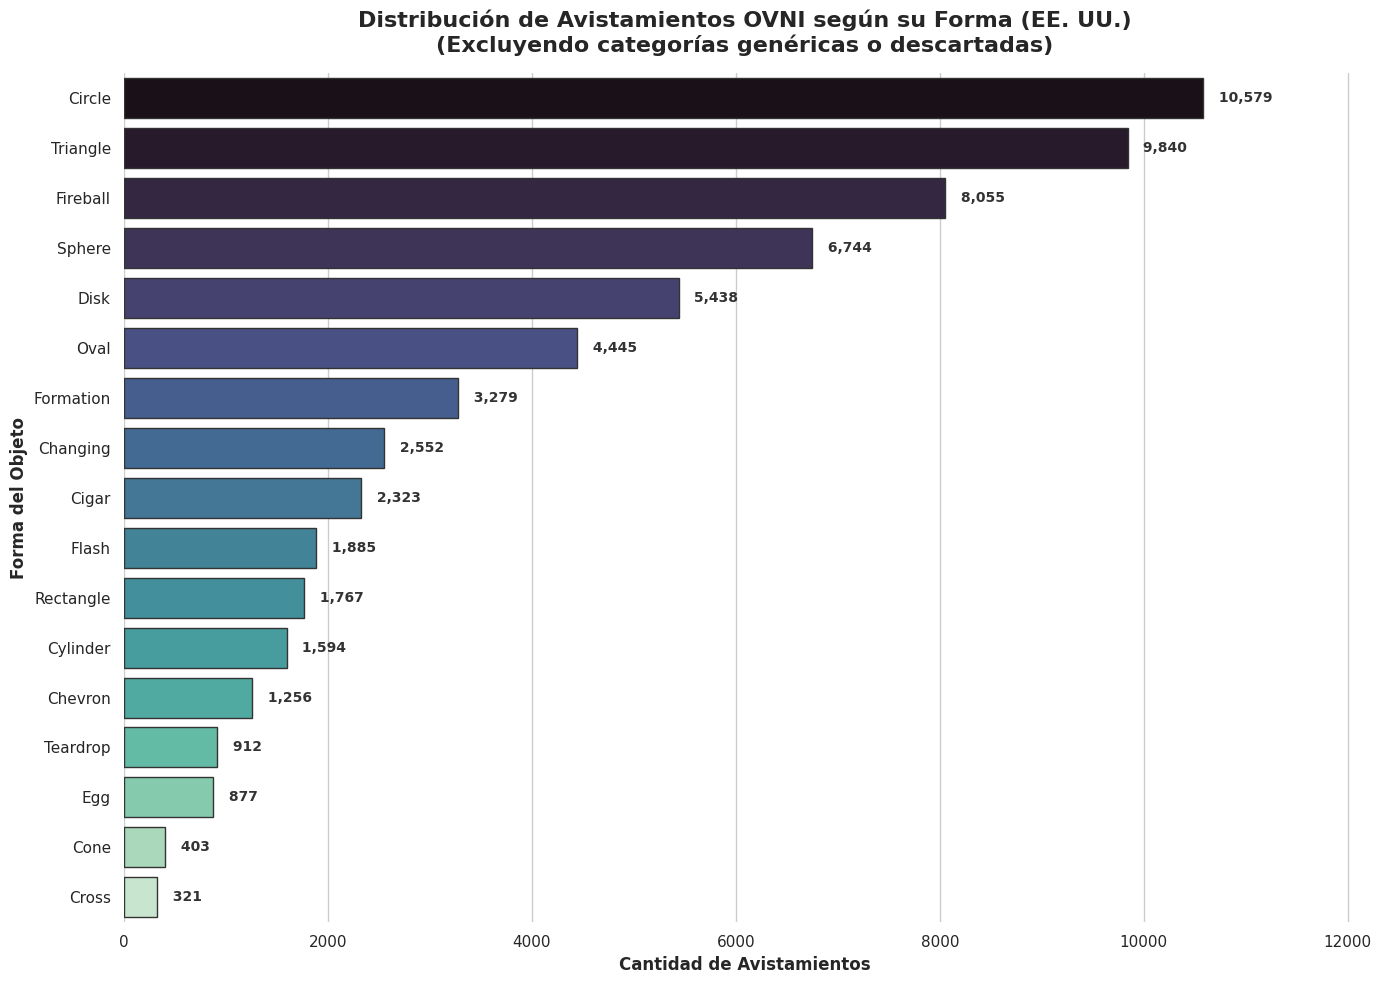

In [16]:
import pandas as pd

# 1. Asegurarse de usar el dataset filtrado por formas (df_filtrado)
# (Asegúrate de haber ejecutado previamente el bloque que define 'descartar' y 'df_filtrado')

# 2. Cantidad de registros por categoría de shape en el dataset filtrado
conteo_shape = df_filtrado["shape"].value_counts(dropna=False)

# 3. Porcentaje de cada categoría sobre el total de registros filtrados
porcentaje_shape = (
    df_filtrado["shape"].value_counts(normalize=True, dropna=False) * 100
)

# 4. Tabla de frecuencias consolidada
distribucion_shape = pd.DataFrame({
    "Cantidad": conteo_shape,
    "Porcentaje (%)": porcentaje_shape.round(2)
})

print("--- Distribución de Shape en el Dataset Filtrado (df_filtrado) ---")
display(distribucion_shape)

#
#

# ============================================
# ANÁLISIS DE LA VARIABLE OBJETIVO: SHAPE (Filtrado EE. UU.)
# ============================================

import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de estilo
sns.set_theme(style="whitegrid")

# 1. Definir la lista de formas a descartar (en minúsculas)
descartar = [
    "light", "other", "unknown", "delta", "crescent",
    "round", "diamond", "hexagon", "flare", "dome", "pyramid", "2013"
]

# 2. Filtrar el DataFrame 'df_usa' excluyendo esas formas (insensible a mayúsculas/minúsculas y espacios)
# Usamos df_usa en lugar de df_procesado
df_filtrado = df_usa[~df_usa["shape"].astype(str).str.lower().str.strip().isin(descartar)].copy()

# --------------------------------------------
# Información general del dataset filtrado
# --------------------------------------------
print("========== VARIABLE OBJETIVO: SHAPE (FILTRADO EE. UU.) ==========")
print(f"\nCantidad de registros originales en df_usa: {len(df_usa):,}")
print(f"Cantidad de registros después del filtro de shape: {len(df_filtrado):,}")
print(f"Cantidad de clases restantes de Shape: {df_filtrado['shape'].nunique()}")

# --------------------------------------------
# Frecuencia de cada clase restante
# --------------------------------------------
frecuencias = (
    df_filtrado["shape"]
    .value_counts()
    .sort_values(ascending=False)
)

print("\nCantidad de registros por forma (filtrado):")
display(frecuencias.to_frame("Cantidad de registros"))

# --------------------------------------------
# Gráfico con Seaborn (Más vistoso)
# --------------------------------------------
plt.figure(figsize=(14, 10))

ax = sns.barplot(
    x=frecuencias.values,
    y=frecuencias.index,
    hue=frecuencias.index,
    palette="mako",
    legend=False,
    edgecolor=".2"
)

plt.title(
    "Distribución de Avistamientos OVNI según su Forma (EE. UU.)\n(Excluyendo categorías genéricas o descartadas)",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Cantidad de Avistamientos", fontsize=12, fontweight="bold")
plt.ylabel("Forma del Objeto", fontsize=12, fontweight="bold")

# Extender ligeramente el eje X para que los números no se corten
plt.xlim(0, frecuencias.values.max() * 1.15)

# Mostrar valores numéricos al lado de cada barra
for i, valor in enumerate(frecuencias.values):
    ax.text(
        valor + (frecuencias.values.max() * 0.01),
        i,
        f" {valor:,}",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="semibold",
        color="#333333"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

## GRÁFICO DE AVISTAMIENTOS POR AÑO EN EE.UU.

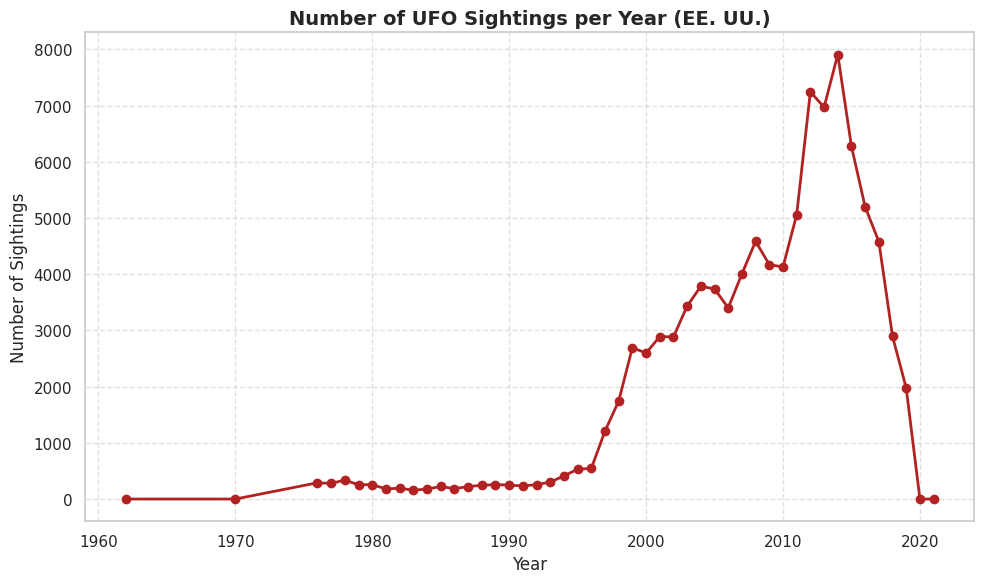

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Agrupar y ordenar por año usando el dataset filtrado (df_usa)
df_year = df_usa["year"].value_counts().reset_index()
df_year.columns = ["year", "sightings"]
df_year = df_year.sort_values("year")

# 2. Configurar y generar la visualización
plt.figure(figsize=(10, 6))
plt.plot(df_year["year"], df_year["sightings"], color="firebrick", marker="o", linewidth=2)

plt.title("Number of UFO Sightings per Year (EE. UU.)", fontsize=14, fontweight="bold")
plt.xlabel("Year", fontsize=12)
plt.ylabel("Number of Sightings", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

plt.show()

## FRECUENCIAS DE AVISTAMIENTOS POR ESTADO EN EE.UU

========== FRECUENCIAS DE AVISTAMIENTOS POR ESTADO (DE MAYOR A MENOR) ==========


,Cantidad de Avistamientos
state,
CA,12728
FL,6227
WA,5305
TX,4643
NY,4379
AZ,3872
PA,3639
IL,3420
OH,3344


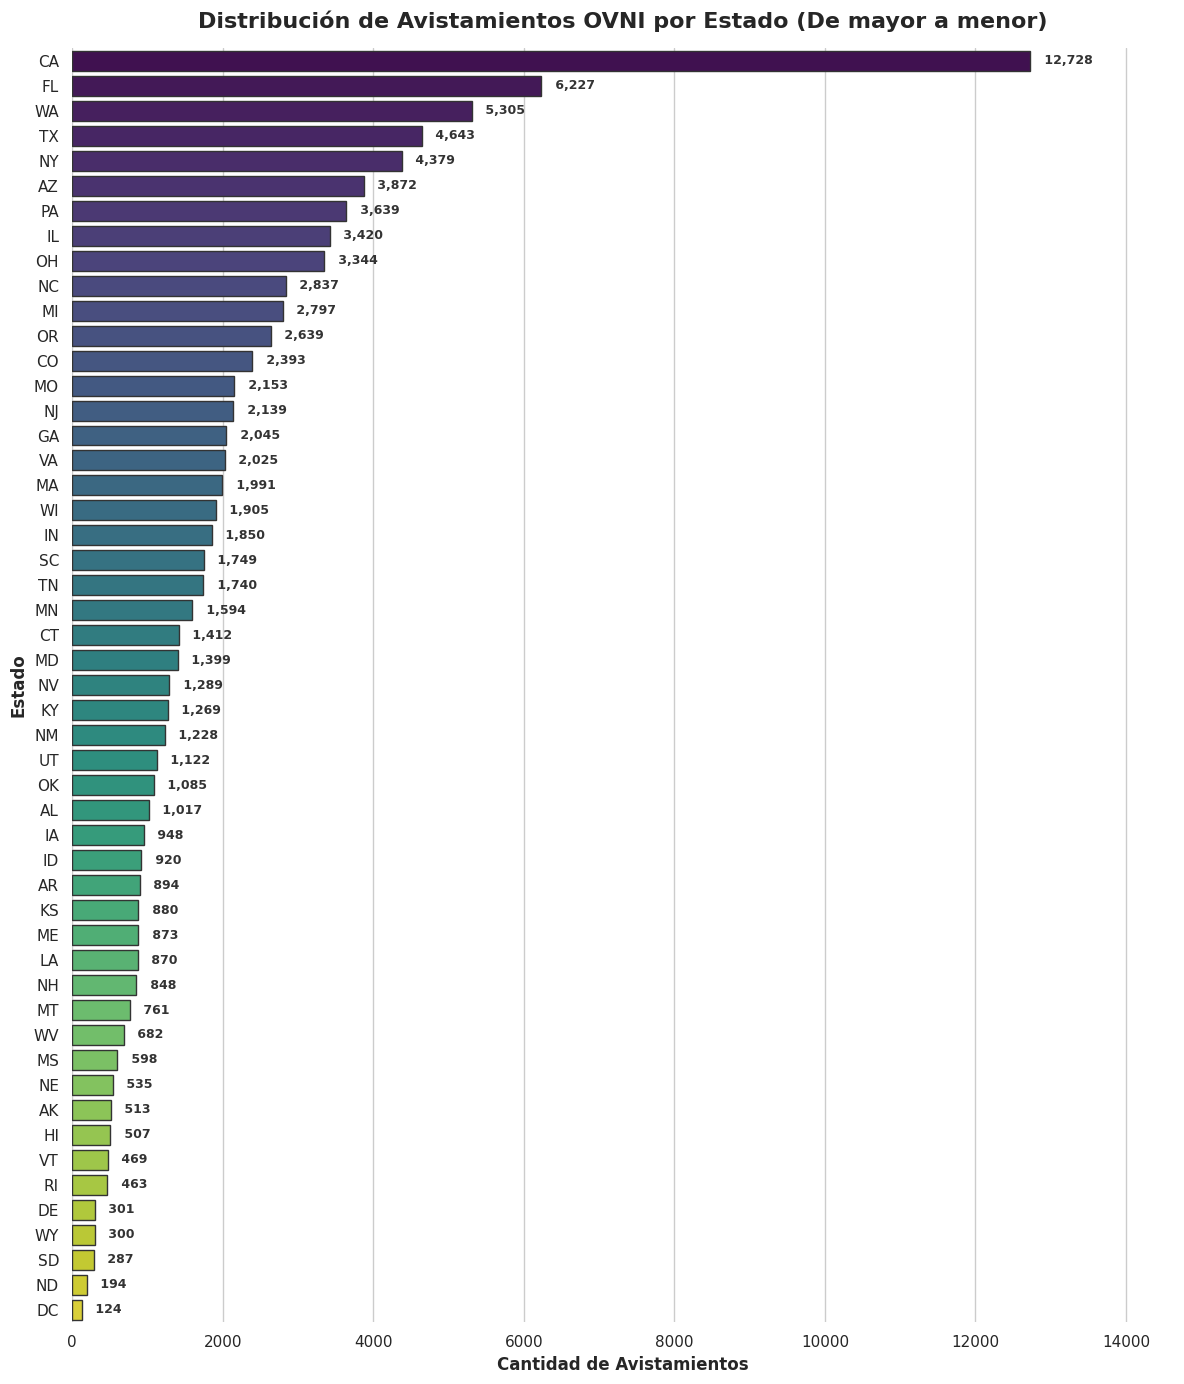

In [18]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración general de estilo
sns.set_theme(style="whitegrid")

# 1. Calcular frecuencias de la columna 'state' ordenadas de mayor a menor (descendente)
frecuencias_state = (
    df_usa["state"]
    .astype(str)
    .str.strip()
    .str.upper()
    .value_counts()
    .sort_values(ascending=False)  # Mayor a menor (el mayor arriba)
)

print("========== FRECUENCIAS DE AVISTAMIENTOS POR ESTADO (DE MAYOR A MENOR) ==========")
display(frecuencias_state.to_frame("Cantidad de Avistamientos"))

# 2. Gráfico de barras horizontales (orden descendente)
plt.figure(figsize=(12, 14))

ax = sns.barplot(
    x=frecuencias_state.values,
    y=frecuencias_state.index,
    hue=frecuencias_state.index,
    palette="viridis",
    legend=False,
    edgecolor=".2"
)

plt.title(
    "Distribución de Avistamientos OVNI por Estado (De mayor a menor)",
    fontsize=16,
    fontweight="bold",
    pad=15
)
plt.xlabel("Cantidad de Avistamientos", fontsize=12, fontweight="bold")
plt.ylabel("Estado", fontsize=12, fontweight="bold")

# Extender ligeramente el eje X para que los números no se corten
plt.xlim(0, frecuencias_state.values.max() * 1.15)

# Mostrar valores numéricos al lado de cada barra
for i, valor in enumerate(frecuencias_state.values):
    ax.text(
        valor + (frecuencias_state.values.max() * 0.01),
        i,
        f" {valor:,}",
        va="center",
        ha="left",
        fontsize=9,
        fontweight="semibold",
        color="#333333"
    )

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

---

## ESCALADO DE VARIABLES para aplicar One Hot Encoding

---



Estas variables poseen una **cardinalidad baja o moderada**, lo que permite transformar las categorías en columnas numéricas sin saturar la dimensionalidad del modelo (*curse of dimensionality*).

## Lista de Variables:

* **`state_grouped`**: Agrupaciones geográficas de estados con cardinalidad controlada.
* **`us_region`**: Divisiones regionales principales de EE. UU. (Norte, Sur, Este, Oeste, etc.).
* **`north_season`**: Estaciones del año en el hemisferio norte (Primavera, Verano, Otoño, Invierno).
* **`quarter_category`**: Trimestres del año ($Q_1, Q_2, Q_3, Q_4$).
* **`month_category`**: Meses del año en formato categórico.
* **`day_category`**: Clasificación del día (ej. día de la semana vs. fin de semana o momentos clave del mes).
* **`time_of_day`**: Franjas horarias discretas (Mañana, Tarde, Noche, Madrugada).
* **`Duracion_clasificacion`**: Categorización general de la duración del evento (Corta, Media, Larga).
* **`duration_category_detailed`**: Categorización detallada por rangos específicos de tiempo.
* **`shape_grouped`**: Formas del fenómeno agrupadas *(aplicar solo si se utiliza como variable predictora $X$)*.

---


In [21]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 1. Cargar el dataset filtrado de Estados Unidos
# (Asegúrate de que 'dataset_usa.csv' esté en tu directorio de trabajo,
# o puedes usar directamente df_usa = df_usa.copy() si ya está en memoria)
ruta_csv_usa = "dataset_usa.csv"
print(f"Cargando el dataset filtrado desde '{ruta_csv_usa}'...")
df_usa = pd.read_csv(ruta_csv_usa)

print(f"Dataset USA cargado. Filas: {df_usa.shape[0]:,}, Columnas: {df_usa.shape[1]}")

# 2. Definir la lista de variables altamente recomendadas para OHE
# Nota: Verificamos que existan en df_usa
variables_ohe = [
    'state_grouped',
    'us_region',
    'north_season',
    'quarter_category',
    'month_category',
    'day_category',
    'time_of_day',
    'Duracion_clasificacion',
    'duration_category_detailed',
    'shape_grouped'
]

# Filtrar solo las columnas que realmente existan en df_usa para evitar errores
variables_ohe = [col for col in variables_ohe if col in df_usa.columns]

# 3. Configurar el ColumnTransformer
# drop='first' evita la multicolinealidad y handle_unknown='ignore' previene errores
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), variables_ohe)
    ],
    remainder='passthrough' # Mantiene el resto de las columnas sin modificar
)

print("\nAplicando OneHotEncoder con ColumnTransformer al dataset de EE. UU. ...")

# 4. Ajustar y transformar el DataFrame de EE. UU.
X_encoded_array = preprocessor.fit_transform(df_usa)

# 5. Obtener los nuevos nombres de las columnas generadas
cat_encoder = preprocessor.named_transformers_['cat']
encoded_cat_cols = cat_encoder.get_feature_names_out(variables_ohe)

# Identificar las columnas que pasaron por 'remainder'
remainder_cols = [col for col in df_usa.columns if col not in variables_ohe]
all_columns = list(encoded_cat_cols) + remainder_cols

# Reconstruir un DataFrame de Pandas para visualizar el resultado claramente
df_usa_encoded = pd.DataFrame(X_encoded_array, columns=all_columns)

print("\n--- Verificación de Aplicación Exitosa (df_usa_encoded) ---")
print(f"Columnas originales (df_usa): {df_usa.shape[1]}")
print(f"Nuevas columnas después de OHE: {df_usa_encoded.shape[1]}")
print(f"Se expandieron {df_usa_encoded.shape[1] - df_usa.shape[1]} columnas binarias nuevas.")

print("\n--- Muestra de los resultados obtenidos (.head()) ---")
display(df_usa_encoded.iloc[:5, :12])

# Opcional: Guardar el dataset codificado listo para modelado
df_usa_encoded.to_csv("dataset_usa_encoded.csv", index=False, encoding="utf-8-sig")
print("\n✅ Dataset codificado guardado exitosamente como 'dataset_usa_encoded.csv'.")

Cargando el dataset filtrado desde 'dataset_usa.csv'...
Dataset USA cargado. Filas: 99,202, Columnas: 27

Aplicando OneHotEncoder con ColumnTransformer al dataset de EE. UU. ...

--- Verificación de Aplicación Exitosa (df_usa_encoded) ---
Columnas originales (df_usa): 27
Nuevas columnas después de OHE: 70
Se expandieron 43 columnas binarias nuevas.

--- Muestra de los resultados obtenidos (.head()) ---


,state_grouped_CA,state_grouped_FL,state_grouped_IL,state_grouped_NY,state_grouped_OH,state_grouped_Other,state_grouped_PA,state_grouped_TX,state_grouped_WA,us_region_Northeast,us_region_Otra / Internacional,us_region_South
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0



✅ Dataset codificado guardado exitosamente como 'dataset_usa_encoded.csv'.


# APLICACIÓN DE MODELOS - PROXIMAMENTE...